# Garbage Classification with Transfer Learning (ResNet-18)
**Computer Vision for Developers — SDAIA Academy · Course Project**

**Goal:** classify images of waste into 6 classes (cardboard, glass, metal, paper, plastic, trash) to support automatic recycling sorting.

**Pipeline:** Kaggle dataset → stratified 70/15/15 split → evaluate *before* training → fine-tune a pretrained ResNet-18 (new head) → curves → evaluate *after* training on the same test set → before/after comparison.

> Runtime: **Runtime → Change runtime type → T4 GPU**. Then **Runtime → Run all**.

## 1. Setup

In [1]:
import os, json, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| torch', torch.__version__)

# ---- Hyperparameters (stated for the rubric) ----
KAGGLE_DATASET = 'asdasdasasdas/garbage-classification'   # change here to use another ImageFolder-style dataset
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 10
LR         = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
os.makedirs('results', exist_ok=True)

Device: cuda | torch 2.14.1+cu130


## 2. Dataset
Downloaded with `kagglehub` (preinstalled in Colab). If Kaggle asks for login, add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's **Secrets** panel (🔑) — never paste the key in the notebook.

In [2]:
DATA_DIR = None   # set a local path here to skip the download
if DATA_DIR is None:
    import kagglehub
    try:
        from google.colab import userdata
        for k in ('KAGGLE_USERNAME', 'KAGGLE_KEY'):
            try: os.environ[k] = userdata.get(k)
            except Exception: pass
    except ImportError:
        pass
    DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
print('Downloaded to:', DATA_DIR)

IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
def find_imagefolder_root(base):
    # Return the folder whose sub-folders (classes) contain the most images.
    best, best_n = None, 0
    for root, dirs, _ in os.walk(base):
        counts = []
        for d in dirs:
            p = os.path.join(root, d)
            n = sum(f.lower().endswith(IMG_EXT) for f in os.listdir(p) if os.path.isfile(os.path.join(p, f)))
            if n > 0: counts.append(n)
        if len(counts) >= 2 and sum(counts) > best_n:
            best, best_n = root, sum(counts)
    return best

ROOT = find_imagefolder_root(DATA_DIR)
print('Class folders found in:', ROOT)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded to: /kaggle/input/garbage-classification
Class folders found in: /kaggle/input/garbage-classification/Garbage classification/Garbage classification


Total images: 2527 | classes: 6


,images
cardboard,403
glass,501
metal,410
paper,594
plastic,482
trash,137


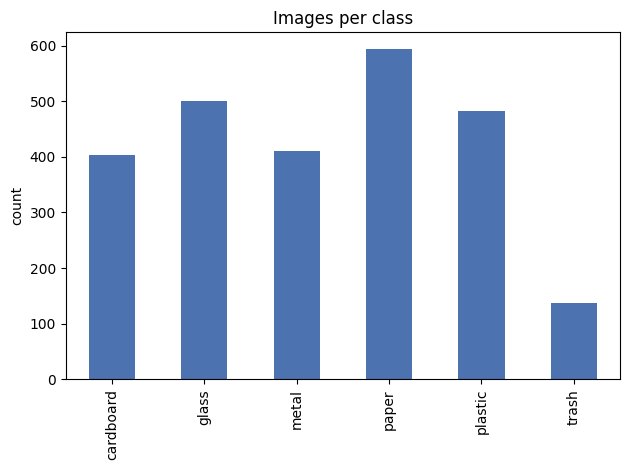

In [3]:
base_ds = datasets.ImageFolder(ROOT)
CLASSES = base_ds.classes
NUM_CLASSES = len(CLASSES)
targets = np.array(base_ds.targets)

counts = pd.Series(targets).value_counts().sort_index()
counts.index = CLASSES
print(f'Total images: {len(base_ds)} | classes: {NUM_CLASSES}')
display(counts.rename('images').to_frame())
counts.plot(kind='bar', title='Images per class', color='#4C72B0'); plt.ylabel('count'); plt.tight_layout()
plt.savefig('results/class_counts.png', dpi=120); plt.show()

### Sample images

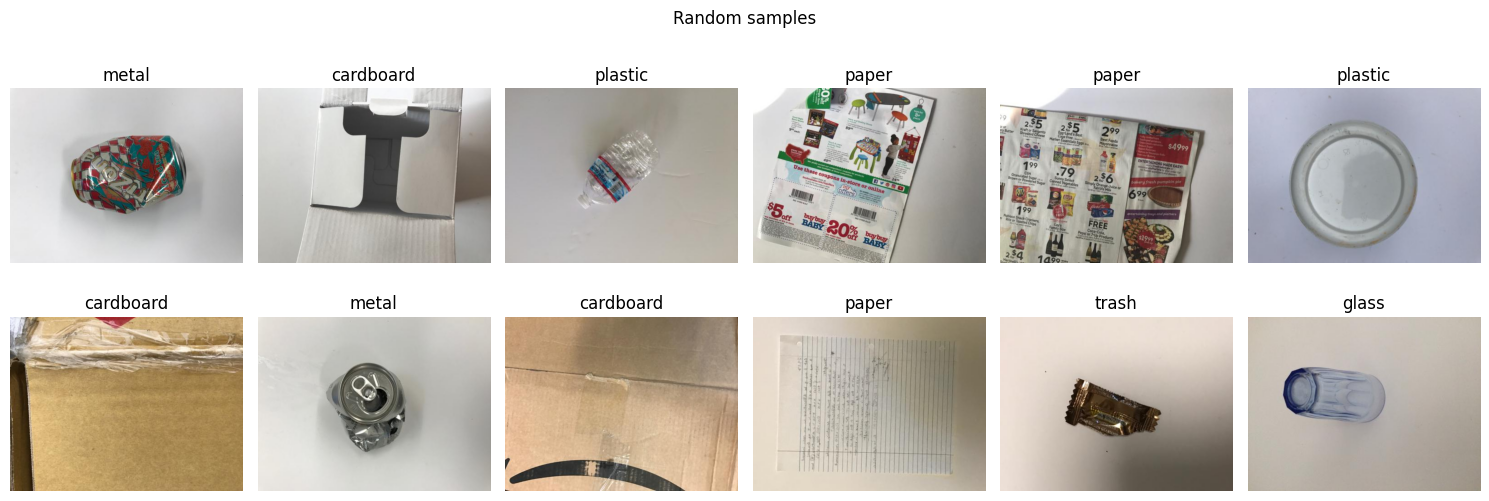

In [4]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(base_ds), 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, i in zip(axes.flat, idx):
    img, y = base_ds[i]
    ax.imshow(img); ax.set_title(CLASSES[y]); ax.axis('off')
plt.suptitle('Random samples'); plt.tight_layout()
plt.savefig('results/samples.png', dpi=120); plt.show()

## 3. Split: 70% train / 15% validation / 15% test (stratified)
The test set is **not touched** until the before/after evaluation.

In [5]:
all_idx = np.arange(len(base_ds))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx  = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)
print(f'train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)}')

split_table = pd.DataFrame({s: pd.Series(targets[ix]).value_counts().sort_index().values
                            for s, ix in [('train', train_idx), ('val', val_idx), ('test', test_idx)]},
                           index=CLASSES)
display(split_table)

train 1768 | val 379 | test 380


,train,val,test
cardboard,282,61,60
glass,350,75,76
metal,287,61,62
paper,416,89,89
plastic,337,72,73
trash,96,21,20


## 4. Transforms and DataLoaders
- **Train:** random resized crop, horizontal flip, small rotation, colour jitter (augmentation that does **not** change the label — a flipped bottle is still a bottle).
- **Val / Test:** resize + centre crop only.
- Normalised with ImageNet mean/std because the backbone was pretrained on ImageNet.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf), train_idx)
val_ds   = Subset(datasets.ImageFolder(ROOT, transform=eval_tf),  val_idx)
test_ds  = Subset(datasets.ImageFolder(ROOT, transform=eval_tf),  test_idx)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, generator=g)
val_loader   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

xb, yb = next(iter(train_loader))
print('Batch shape (N, C, H, W):', tuple(xb.shape))

Batch shape (N, C, H, W): (32, 3, 224, 224)


## 5. Model: pretrained ResNet-18 with a new head
Strategy from Day 1 (*little data, images similar to ImageNet*): keep the pretrained backbone, replace the final layer with a new 6-class head, freeze the early layers and fine-tune only **`layer4` + the head**.

In [7]:
def build_model():
    set_seed()
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.layer4.parameters():
        p.requires_grad = True
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))  # new head, random weights
    return m.to(DEVICE)

model = build_model()
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parameters: {n_total:,} total | {n_train:,} trainable')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


Parameters: 11,179,590 total | 8,396,806 trainable


## 6. Evaluation function (used before AND after training)

In [8]:
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()                      # dropout off, BatchNorm uses saved statistics
    total_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    return {'loss': total_loss / len(labels), 'accuracy': accuracy_score(labels, preds),
            'precision': p, 'recall': r, 'f1': f1}, preds, labels

def plot_cm(labels, preds, title, path):
    cm = confusion_matrix(labels, preds, labels=range(NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(title); plt.tight_layout(); plt.savefig(path, dpi=120); plt.show()

## 7. Before training — evaluate on the test set
The head has random weights, so results should be close to guessing (≈ 1 / number of classes).

Random-guess accuracy ≈ 0.167
{'loss': 1.889, 'accuracy': 0.1868, 'precision': 0.1339, 'recall': 0.1502, 'f1': 0.1093}


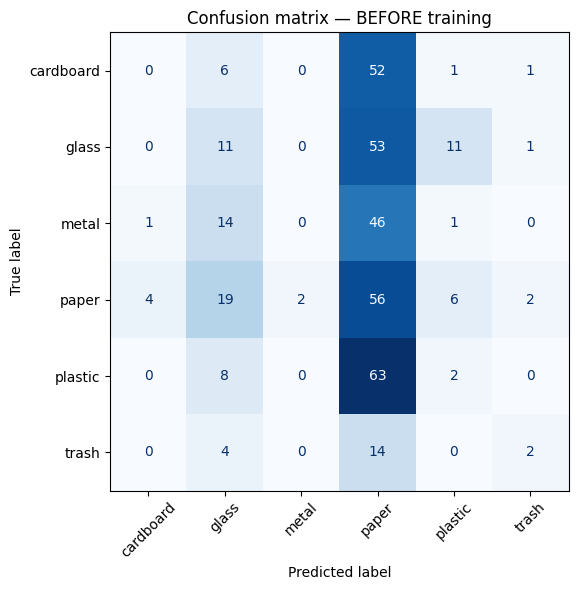

In [9]:
before, preds_b, labels_b = evaluate(model, test_loader)
print(f'Random-guess accuracy ≈ {1/NUM_CLASSES:.3f}')
print({k: round(v, 4) for k, v in before.items()})
plot_cm(labels_b, preds_b, 'Confusion matrix — BEFORE training', 'results/cm_before.png')

## 8. Training

In [10]:
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_acc, best_state = 0.0, None
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    run_loss, correct, seen = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)                    # forward
        loss = criterion(out, y)          # how wrong
        optimizer.zero_grad()             # clear old gradients
        loss.backward()                   # compute gradients
        optimizer.step()                  # update weights
        run_loss += loss.item() * x.size(0)
        correct  += (out.argmax(1) == y).sum().item(); seen += x.size(0)
    scheduler.step()
    val_m, _, _ = evaluate(model, val_loader)
    history['train_loss'].append(run_loss / seen); history['train_acc'].append(correct / seen)
    history['val_loss'].append(val_m['loss']);     history['val_acc'].append(val_m['accuracy'])
    if val_m['accuracy'] > best_acc:      # keep the best checkpoint (by validation accuracy)
        best_acc, best_state = val_m['accuracy'], copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.3f} "
          f"| val loss {val_m['loss']:.4f} acc {val_m['accuracy']:.3f}")
print(f'Training time: {(time.time()-t0)/60:.1f} min | best val acc {best_acc:.3f}')
model.load_state_dict(best_state)
torch.save(best_state, 'results/best_model.pt')

Epoch  1/10 | train loss 0.8382 acc 0.701 | val loss 0.7565 acc 0.752
Epoch  2/10 | train loss 0.4629 acc 0.837 | val loss 0.5540 acc 0.797
Epoch  3/10 | train loss 0.3403 acc 0.883 | val loss 0.5263 acc 0.828
Epoch  4/10 | train loss 0.2343 acc 0.923 | val loss 0.4080 acc 0.852
Epoch  5/10 | train loss 0.1865 acc 0.940 | val loss 0.5509 acc 0.839
Epoch  6/10 | train loss 0.1277 acc 0.955 | val loss 0.4403 acc 0.871
Epoch  7/10 | train loss 0.0967 acc 0.969 | val loss 0.4553 acc 0.887
Epoch  8/10 | train loss 0.0728 acc 0.977 | val loss 0.4307 acc 0.863
Epoch  9/10 | train loss 0.0493 acc 0.988 | val loss 0.3702 acc 0.889
Epoch 10/10 | train loss 0.0326 acc 0.995 | val loss 0.3686 acc 0.881
Training time: 2.4 min | best val acc 0.889


## 9. Learning curves

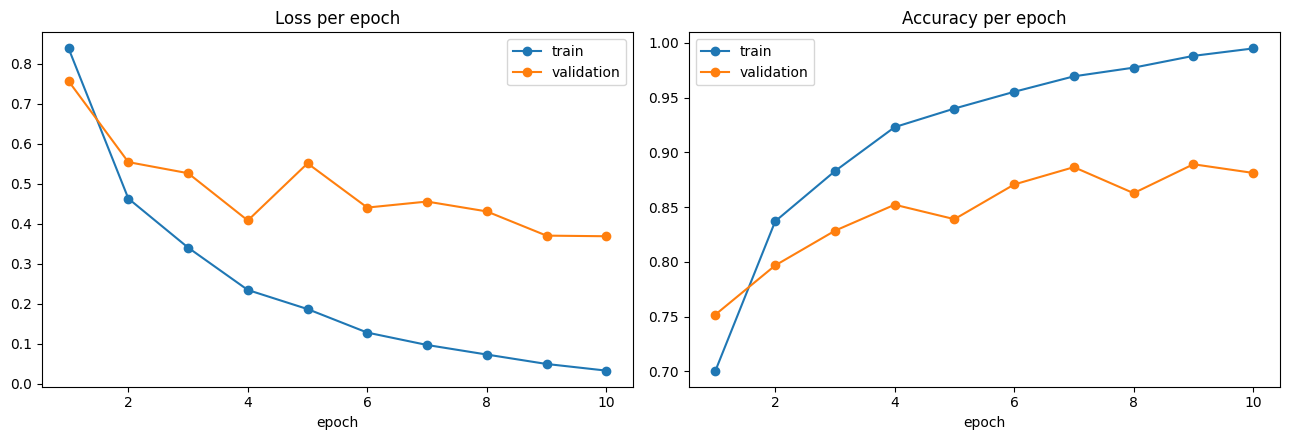

Final train-val accuracy gap: 0.114
Reading: if both losses fall together and the gap stays small → good fit; if train loss keeps falling while val loss rises → overfitting.


In [11]:
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ep, history['train_loss'], 'o-', label='train'); axes[0].plot(ep, history['val_loss'], 'o-', label='validation')
axes[0].set_title('Loss per epoch'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(ep, history['train_acc'], 'o-', label='train'); axes[1].plot(ep, history['val_acc'], 'o-', label='validation')
axes[1].set_title('Accuracy per epoch'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig('results/curves.png', dpi=120); plt.show()

gap = history['train_acc'][-1] - history['val_acc'][-1]
print(f'Final train-val accuracy gap: {gap:.3f}')
print('Reading: if both losses fall together and the gap stays small → good fit; '
      'if train loss keeps falling while val loss rises → overfitting.')

## 10. After training — same test set, same metrics

{'loss': 0.2848, 'accuracy': 0.9132, 'precision': 0.911, 'recall': 0.8921, 'f1': 0.8999}


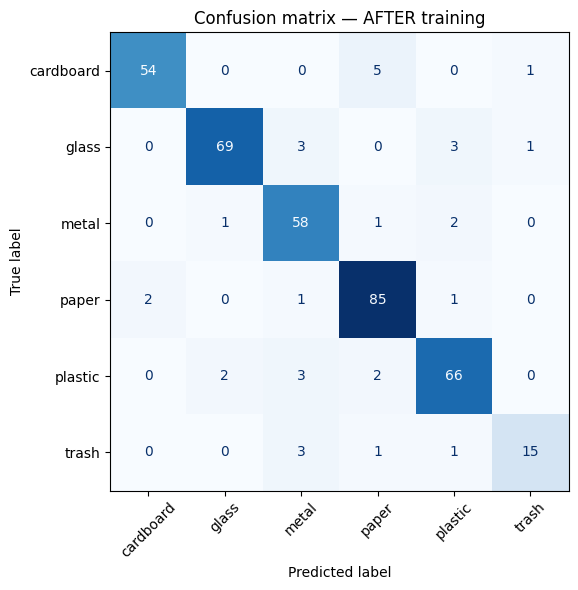

              precision    recall  f1-score   support

   cardboard      0.964     0.900     0.931        60
       glass      0.958     0.908     0.932        76
       metal      0.853     0.935     0.892        62
       paper      0.904     0.955     0.929        89
     plastic      0.904     0.904     0.904        73
       trash      0.882     0.750     0.811        20

    accuracy                          0.913       380
   macro avg      0.911     0.892     0.900       380
weighted avg      0.915     0.913     0.913       380



In [12]:
after, preds_a, labels_a = evaluate(model, test_loader)
print({k: round(v, 4) for k, v in after.items()})
plot_cm(labels_a, preds_a, 'Confusion matrix — AFTER training', 'results/cm_after.png')
print(classification_report(labels_a, preds_a, target_names=CLASSES, digits=3, zero_division=0))

## 11. Before vs after

In [13]:
comp = pd.DataFrame({'Before training': before, 'After training': after}).T
comp = comp[['loss', 'accuracy', 'precision', 'recall', 'f1']].round(4)
display(comp)
comp.to_csv('results/before_after.csv')
with open('results/metrics.json', 'w') as f:
    json.dump({'before': before, 'after': after, 'history': history,
               'hyperparameters': {'epochs': EPOCHS, 'lr': LR, 'batch_size': BATCH_SIZE,
                                   'img_size': IMG_SIZE, 'weight_decay': WEIGHT_DECAY}}, f, indent=2)
try:
    print(comp.to_markdown())   # paste this table into the README
except ImportError:
    print(comp.to_string())

,loss,accuracy,precision,recall,f1
Before training,1.8890,0.1868,0.1339,0.1502,0.1093
After training,0.2848,0.9132,0.9110,0.8921,0.8999


|                 |   loss |   accuracy |   precision |   recall |     f1 |
|:----------------|-------:|-----------:|------------:|---------:|-------:|
| Before training | 1.889  |     0.1868 |      0.1339 |   0.1502 | 0.1093 |
| After training  | 0.2848 |     0.9132 |      0.911  |   0.8921 | 0.8999 |


### Misclassified test images

33 of 380 test images misclassified


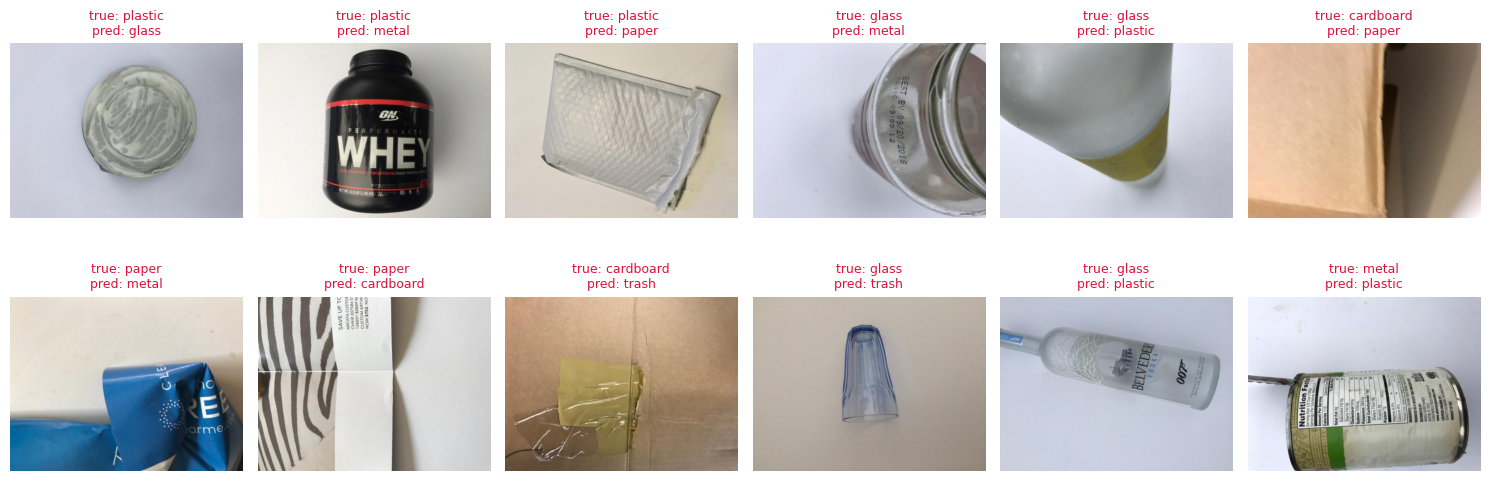

In [14]:
wrong = np.where(preds_a != labels_a)[0]
print(f'{len(wrong)} of {len(labels_a)} test images misclassified')
show = wrong[:12]
if len(show):
    cols = 6; rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 2.8 * rows), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, i in zip(axes.flat, show):
        img, _ = base_ds[test_idx[i]]
        ax.imshow(img); ax.set_title(f'true: {CLASSES[labels_a[i]]}\npred: {CLASSES[preds_a[i]]}', fontsize=9, color='crimson')
    plt.tight_layout(); plt.savefig('results/misclassified.png', dpi=120); plt.show()

## 12. What changed and why
- **Before:** the new head had random weights, so predictions were essentially guesses — accuracy near 1/6 and a confusion matrix with no clear diagonal.
- **After:** the head (and `layer4`) learned to map ImageNet features to waste classes. Accuracy, precision, recall and F1 rise and the confusion matrix becomes strongly diagonal.
- **Why so fast with little data:** transfer learning — the backbone already detects edges, textures and object parts from 1.2 M ImageNet images; we only adapt the last stage.
- **Remaining errors:** check the confusion matrix — visually similar materials (e.g. glass vs plastic, paper vs cardboard) are the expected confusions.
- **Next steps:** fine-tune all layers with a smaller learning rate, more epochs, class-balanced sampling for the smallest class (`trash`), or test-time augmentation.